DATASET 2     "Give me some credit" kaggle

In [7]:
##IMPORT LIBRERIRE E DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, RocCurveDisplay

from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

# Caricamento dataset (Give Me Some Credit - training set)
df = pd.read_csv("cs-training.csv", index_col=0)

# Rename target
df.rename(columns={'SeriousDlqin2yrs': 'default'}, inplace=True)
df.head()



,default,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [8]:
#ISPEZIONE DEL DATASET

y = df["default"]
X = df.drop(columns=["default"])



import numpy as np

print("=== dtypes del DataFrame X ===")
print(X.dtypes)           

numeriche  = X.select_dtypes(include=[np.number]).columns.tolist()
categoric  = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nVariabili numeriche :", numeriche)
print("Variabili categoriche:", categoric if categoric else "— nessuna trovata —")


feature_types = ["continuous" if col in numeriche else "categorical" for col in X.columns]
print("\nfeature_types (ordine corrisponde a X.columns):")
print(feature_types)

#tutte continue, nessuna categorica trovata nel dataset
#int --> numero intero (nessuna virgola)
#float --> numero decimale o con NA

=== dtypes del DataFrame X ===
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

Variabili numeriche : ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
Variabili categoriche: — nessuna trovata —

feature_types (ordine corrisponde a X.columns):
['continuous', 'continuous', 'continuous', 'continuous', 'continuous', 'continuous', '

In [7]:
# ---------------------------------------
# REPORT ESPLORATIVO - Give Me Some Credit
# ---------------------------------------

from ydata_profiling import ProfileReport

# Crea il profilo
profile = ProfileReport(
    df,
    title="Profilo Give Me Some Credit Dataset",
    explorative=True,
    correlations={"pearson": {"calculate": True}},
    missing_diagrams={"heatmap": True, "dendrogram": True}
)

# Mostra direttamente nel notebook
profile.to_notebook_iframe()


Python(61378) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(61379) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:00<00:00, 11.80it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [9]:
#conteggio della proporzione di default

df["default"].value_counts(normalize=True)


default
0    0.93316
1    0.06684
Name: proportion, dtype: float64

In [10]:
# ANALISI  NaN

#conteggi distribuzione per variabili dei conteggi
for col in [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]:
   
    print(X[col].value_counts().sort_index())

NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
6        140
7         54
8         25
9         12
10         4
11         1
12         2
13         1
96         5
98       264
Name: count, dtype: int64
NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
4        105
5         34
6         16
7          9
8          2
9          1
11         1
96         5
98       264
Name: count, dtype: int64
NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: count, dtype: int64


In [11]:
# Ricodifica 96/98 in NaN per EBM, non è fisicamente possibile essere in ritardo 98 e 96 volte in due anni.
cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

for col in cols:
    X[col] = X[col].replace({96: np.nan, 98: np.nan})

In [12]:
#verifichiamo se ci sono i NAN imputati (variabili con NA sono indicati come Float)


for col in cols:
    print(f"{col}: dtype → {X[col].dtype},  NaN → {X[col].isna().sum()}")

# 3) Distribuzione completa (inclusi i NaN) – facoltativo
for col in cols:
    print(f"\n{col} – Distribuzione (NaN inclusi):")
    print(X[col].value_counts(dropna=False).sort_index())

NumberOfTime30-59DaysPastDueNotWorse: dtype → float64,  NaN → 269
NumberOfTime60-89DaysPastDueNotWorse: dtype → float64,  NaN → 269
NumberOfTimes90DaysLate: dtype → float64,  NaN → 269

NumberOfTime30-59DaysPastDueNotWorse – Distribuzione (NaN inclusi):
NumberOfTime30-59DaysPastDueNotWorse
0.0     126018
1.0      16033
2.0       4598
3.0       1754
4.0        747
5.0        342
6.0        140
7.0         54
8.0         25
9.0         12
10.0         4
11.0         1
12.0         2
13.0         1
NaN        269
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse – Distribuzione (NaN inclusi):
NumberOfTime60-89DaysPastDueNotWorse
0.0     142396
1.0       5731
2.0       1118
3.0        318
4.0        105
5.0         34
6.0         16
7.0          9
8.0          2
9.0          1
11.0         1
NaN        269
Name: count, dtype: int64

NumberOfTimes90DaysLate – Distribuzione (NaN inclusi):
NumberOfTimes90DaysLate
0.0     141662
1.0       5243
2.0       1555
3.0        667
4.0   

In [13]:
#verifichiamo anomalie per "età"

print("Descrizione iniziale di age:")
print(X["age"].describe())



print("\nValori anomali:")
print("Valori <= 0:", (X["age"] <= 0).sum())
print("Valori < 18:", (X["age"] < 18).sum())
print("Valori > 95:", (X["age"] > 95).sum())

# 1) Ricodifica valori illegali/inverosimili a NaN
X["age"] = X["age"].replace({0: np.nan})    # età 0 impossibile
X.loc[X["age"] > 95, "age"] = np.nan        # sopra 95 la consideriamo outlier

# 3) Statistiche di controllo post-trattamento
print(X["age"].describe())
print("Età <18:", (X["age"] < 18).sum())
print("Età >95:", (X["age"] > 95).sum())
print("NaN residui:", X["age"].isna().sum())

Descrizione iniziale di age:
count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64

Valori anomali:
Valori <= 0: 1
Valori < 18: 1
Valori > 95: 63
count    149936.000000
mean         52.276151
std          14.743894
min          21.000000
25%          41.000000
50%          52.000000
75%          63.000000
max          95.000000
Name: age, dtype: float64
Età <18: 0
Età >95: 0
NaN residui: 64


In [14]:

# === Analisi valori della variabile RevolvingUtilizationOfUnsecuredLines ===

col = "RevolvingUtilizationOfUnsecuredLines"

print(f"Statistiche descrittive per {col}:")
print(X[col].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_string())

# Conteggio dei valori anomali > 1
n_tot = len(X)
n_over1 = (X[col] > 1).sum()
perc_over1 = n_over1 / n_tot * 100

print(f"\nNumero di osservazioni > 1: {n_over1:,} ({perc_over1:.2f}%)")

# Verifica di quanti valori estremi esistono
n_over10 = (X[col] > 10).sum()
n_over100 = (X[col] > 100).sum()
n_over1000 = (X[col] > 1000).sum()
n_over10000 = (X[col] > 10000).sum()

print(f">10: {n_over10:,}   |   >100: {n_over100:,}   |   >1000: {n_over1000:,}   |   >10000: {n_over10000:,}")

# Frequenze dei valori più estremi (per capire cosa c'è dentro)
print("\nValori più alti osservati:")
print(X[col].nlargest(10))


Statistiche descrittive per RevolvingUtilizationOfUnsecuredLines:
count    150000.000000
mean          6.048438
std         249.755371
min           0.000000
50%           0.154181
90%           0.981278
95%           1.000000
99%           1.092956
99.9%      1571.006000
max       50708.000000

Numero di osservazioni > 1: 3,321 (2.21%)
>10: 241   |   >100: 223   |   >1000: 172   |   >10000: 16

Valori più alti osservati:
85490     50708.0
31415     29110.0
16957     22198.0
149161    22000.0
149280    20514.0
117316    18300.0
21979     17441.0
124534    13930.0
72593     13498.0
71706     13400.0
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64


In [15]:
# === CORREZIONE VARIABILE RevolvingUtilizationOfUnsecuredLines ===

X["RevolvingUtilizationOfUnsecuredLines"] = X["RevolvingUtilizationOfUnsecuredLines"].clip(upper=1)

# Verifica post-troncamento
print(X["RevolvingUtilizationOfUnsecuredLines"].describe())
print("Valori > 1 dopo clipping:", (X["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())


count    150000.000000
mean          0.319196
std           0.349481
min           0.000000
25%           0.029867
50%           0.154181
75%           0.559046
max           1.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
Valori > 1 dopo clipping: 0


In [16]:
# === Analisi valori della variabile debtratio ===

col = "DebtRatio"

print(f"Statistiche descrittive per {col}:")
print(X[col].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_string())

# Conteggio dei valori anomali > 1
n_tot = len(X)
n_over1 = (X[col] > 1).sum()
perc_over1 = n_over1 / n_tot * 100

print(f"\nNumero di osservazioni > 1: {n_over1:,} ({perc_over1:.2f}%)")

# Verifica di quanti valori estremi esistono
n_over10 = (X[col] > 10).sum()
n_over100 = (X[col] > 100).sum()
n_over1000 = (X[col] > 1000).sum()
n_over10000 = (X[col] > 10000).sum()

print(f">10: {n_over10:,}   |   >100: {n_over100:,}   |   >1000: {n_over1000:,}   |   >10000: {n_over10000:,}")

# Frequenze dei valori più estremi
print("\nValori più alti osservati:")
print(X[col].nlargest(10))



Statistiche descrittive per DebtRatio:
count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
50%           0.366508
90%        1267.000000
95%        2449.000000
99%        4979.040000
99.9%     10613.074000
max      329664.000000

Numero di osservazioni > 1: 35,137 (23.42%)
>10: 28,877   |   >100: 24,380   |   >1000: 16,892   |   >10000: 180

Valori più alti osservati:
60153     329664.0
36601     326442.0
127048    307001.0
58901     220516.0
4855      168835.0
7514      110952.0
103042    106885.0
69846     101320.0
66786      61907.0
53683      61106.5
Name: DebtRatio, dtype: float64


In [17]:
X["DebtRatio"] = X["DebtRatio"].clip(upper=3)

print(X["DebtRatio"].describe())
print("Valori > 5 dopo clipping:", (X["DebtRatio"] > 3).sum())
print("Valori > 1 ", (X["DebtRatio"] > 1).sum())

count    150000.000000
mean          0.886964
std           1.106173
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max           3.000000
Name: DebtRatio, dtype: float64
Valori > 5 dopo clipping: 0
Valori > 1  35137


In [18]:
# === Analisi valori della variabile MonthlyIncome ===



col = "MonthlyIncome"

print(f"Statistiche descrittive per {col}:")
print(X[col].describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).to_string())

# Conteggio dei valori mancanti
n_missing = X[col].isna().sum()
print(f"\nValori mancanti: {n_missing} ({n_missing/len(X)*100:.2f}%)")

# Conteggio dei valori estremi
n_over20k = (X[col] > 20000).sum()
n_over50k = (X[col] > 50000).sum()
n_over100k = (X[col] > 100000).sum()
n_over1M = (X[col] > 1000000).sum()

print(f"\nValori >20k: {n_over20k:,}  |  >50k: {n_over50k:,}  |  >100k: {n_over100k:,}  |  >1M: {n_over1M:,}")

# Valori più alti osservati
print("\nValori più alti osservati:")
print(X[col].nlargest(10))


Statistiche descrittive per MonthlyIncome:
count    1.202690e+05
mean     6.670221e+03
std      1.438467e+04
min      0.000000e+00
50%      5.400000e+03
90%      1.166600e+04
95%      1.458760e+04
99%      2.500000e+04
99.9%    7.839575e+04
max      3.008750e+06

Valori mancanti: 29731 (19.82%)

Valori >20k: 2,103  |  >50k: 301  |  >100k: 70  |  >1M: 4

Valori più alti osservati:
73764     3008750.0
137141    1794060.0
111366    1560100.0
50641     1072500.0
122544     835040.0
123292     730483.0
93565      702500.0
96550      699530.0
119137     649587.0
37079      629000.0
Name: MonthlyIncome, dtype: float64


In [20]:
X["MonthlyIncome"] = X["MonthlyIncome"].clip(upper=30000)


In [21]:
#statistiche descrittive

import pandas as pd

# Colonne numeriche (tutte in X_na)
num_cols = X.select_dtypes(include="number").columns

# Statistiche base
num_desc = X[num_cols].describe().T

# Aggiungiamo dtype e numero di missing
num_desc["dtype"]   = X[num_cols].dtypes
num_desc["missing"] = X[num_cols].isna().sum()

# Riorganizzazione colonne
num_desc = num_desc[
    ["dtype", "missing", "count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)

# Stampa 
print("=== STATISTICHE DESCRITTIVE PER TUTTE LE VARIABILI NUMERICHE IN X===")
display(num_desc)

=== STATISTICHE DESCRITTIVE PER TUTTE LE VARIABILI NUMERICHE IN X===


,dtype,missing,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,float64,0,150000.0,0.32,0.35,0.0,0.03,0.15,0.56,1.0
age,float64,64,149936.0,52.28,14.74,21.0,41.00,52.00,63.00,95.0
NumberOfTime30-59DaysPastDueNotWorse,float64,269,149731.0,0.25,0.70,0.0,0.00,0.00,0.00,13.0
DebtRatio,float64,0,150000.0,0.89,1.11,0.0,0.18,0.37,0.87,3.0
MonthlyIncome,float64,29731,120269.0,6390.57,4553.72,0.0,3400.00,5400.00,8249.00,30000.0
NumberOfOpenCreditLinesAndLoans,int64,0,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,float64,269,149731.0,0.09,0.49,0.0,0.00,0.00,0.00,17.0
NumberRealEstateLoansOrLines,int64,0,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,float64,269,149731.0,0.06,0.33,0.0,0.00,0.00,0.00,11.0
NumberOfDependents,float64,3924,146076.0,0.76,1.12,0.0,0.00,0.00,1.00,20.0


In [22]:
#  Split train/test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

# dataset con mediana
from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_imp  = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)
print("Totale NA in X_train_imp:", X_train_imp.isna().sum().sum())
print("Totale NA in X_test_imp:",  X_test_imp.isna().sum().sum())


Totale NA in X_train_imp: 0
Totale NA in X_test_imp: 0


###    EBM    ########

In [23]:
#### confronto tra EBM su dataset con NA e su dataset con valori imputati

from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight

#  Calcolo pesi di bilanciamento automatici
w_train = compute_sample_weight(class_weight="balanced", y=y_train)

#  EBM base – dataset con NA
ebm_na = ExplainableBoostingClassifier(random_state=42)
ebm_na.fit(X_train, y_train, sample_weight=w_train)

y_pred_na = ebm_na.predict(X_test)
y_proba_na = ebm_na.predict_proba(X_test)[:, 1]

acc_na = accuracy_score(y_test, y_pred_na)
auc_na = roc_auc_score(y_test, y_proba_na)

print("=== EBM con NA ===")
print(f"Accuracy: {acc_na:.4f}")
print(f"AUC: {auc_na:.4f}")

#  EBM base – dataset imputato con mediana
ebm_imp = ExplainableBoostingClassifier(random_state=42)
ebm_imp.fit(X_train_imp, y_train, sample_weight=w_train)

y_pred_imp = ebm_imp.predict(X_test_imp)
y_proba_imp = ebm_imp.predict_proba(X_test_imp)[:, 1]

acc_imp = accuracy_score(y_test, y_pred_imp)
auc_imp = roc_auc_score(y_test, y_proba_imp)

print("\n=== EBM con imputazione (mediana) ===")
print(f"Accuracy: {acc_imp:.4f}")
print(f"AUC: {auc_imp:.4f}")


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/interpret/glassbox/_ebm/_ebm.py:815: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


=== EBM con NA ===
Accuracy: 0.8031
AUC: 0.8669

=== EBM con imputazione (mediana) ===
Accuracy: 0.8020
AUC: 0.8664


In [24]:
### EBM con Interazioni ###

# 2️⃣ 
ebm_na_int = ExplainableBoostingClassifier(
    interactions=5,
    max_bins=264,
    max_leaves=3,
    learning_rate=0.01,
    outer_bags=10,
    inner_bags=0,
    random_state=42,
    early_stopping_rounds=50,
    validation_size=0.15
)
ebm_na_int.fit(X_train, y_train, sample_weight=w_train)

y_pred_na_int = ebm_na_int.predict(X_test)
y_proba_na_int = ebm_na_int.predict_proba(X_test)[:, 1]

acc_na_int = accuracy_score(y_test, y_pred_na_int)
auc_na_int = roc_auc_score(y_test, y_proba_na_int)

print("=== EBM con NA ===")
print(f"Accuracy: {acc_na_int:.4f}")
print(f"AUC: {auc_na_int:.4f}")

#Ottieni spiegazioni globali dal modello EBM con interazioni
ebm_global = ebm_na_int.explain_global()

# Visualizza tutte le feature e le interazioni (interattivo, tramite ipywidgets)
show(ebm_global)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/interpret/glassbox/_ebm/_ebm.py:815: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


=== EBM con NA ===
Accuracy: 0.8005
AUC: 0.8650


<!-- http://127.0.0.1:7392/4640589104/ -->

In [25]:

# EBM ottimizzato – tuning migliore rilevato
ebm_tuned = ExplainableBoostingClassifier(
    interactions=0,
    max_bins=264,
    max_leaves=3,
    learning_rate=0.01,
    outer_bags=10,
    inner_bags=0,
    random_state=42,
    early_stopping_rounds=50,
    validation_size=0.15
)

# Fit su dataset con NA
ebm_tuned.fit(X_train, y_train, sample_weight=w_train)

# Predizioni
y_pred = ebm_tuned.predict(X_test)
y_proba = ebm_tuned.predict_proba(X_test)[:, 1]

# Metriche
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("=== EBM Tuned – Dataset con NA ===")
print(f"Accuracy: {acc:.4f}")
print(f"AUC: {auc:.4f}")


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/interpret/glassbox/_ebm/_ebm.py:815: UserWarning:

Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]



=== EBM Tuned – Dataset con NA ===
Accuracy: 0.8109
AUC: 0.8638


In [26]:
#Ottieni spiegazioni globali dal modello EBM con interazioni
ebm_global = ebm_tuned.explain_global()

# Visualizza tutte le feature e le interazioni (interattivo, tramite ipywidgets)
show(ebm_global)

<!-- http://127.0.0.1:7392/4847502160/ -->

In [27]:
#Mostro il bin dei missing per due variabili a titolo di esempio.

feat1 = "MonthlyIncome"
feat2 = "NumberOfDependents"

# Ottieni l'indice delle variabili nel modello EBM
idx1 = list(ebm_na.feature_names_in_).index(feat1)
idx2 = list(ebm_na.feature_names_in_).index(feat2)

# Estrazione dei term scores completi (lista di valori per ciascun bin)
scores1 = ebm_na.term_scores_[idx1]
scores2 = ebm_na.term_scores_[idx2]

# Visualizza  il bin "missing" (indice 0)
print(f"--- {feat1} ---")
print(f"Bin 0 (missing) log-odds: {scores1[0]:.4f}")

print(f"\n--- {feat2} ---")
print(f"Bin 0 (missing) log-odds: {scores2[0]:.4f}")

#  mostro anche quanti bin totali ha ciascuna variabile
print(f"\n{feat1} → n° bin totali: {len(scores1)}")
print(f"{feat2} → n° bin totali: {len(scores2)}")


--- MonthlyIncome ---
Bin 0 (missing) log-odds: -0.3622

--- NumberOfDependents ---
Bin 0 (missing) log-odds: -0.1214

MonthlyIncome → n° bin totali: 1019
NumberOfDependents → n° bin totali: 12


In [28]:
from scipy.special import expit
import pandas as pd
import numpy as np

# ==========================================================
# TABELLA RIDOTTA DEI MISSING 
# ==========================================================

rows = []

for i, feat in enumerate(ebm_tuned.feature_names_in_):
    # log-odds associato al bin dei missing
    logodds_nan = ebm_tuned.term_scores_[i][0]
    mask_train_nan = X_train[feat].isna()
    mask_test_nan  = X_test[feat].isna()
#mask serve per filtrare dai dati i missing, come conteggio (maschera boleana 1=NaN 0=valore)
    if not mask_train_nan.any():
        continue  # se non ci sono NaN nel train, salta

    rows.append({
        "Variabile": feat,
        "% Missing (train)": round(mask_train_nan.mean() * 100, 2),
        "% Missing (test)":  round(mask_test_nan.mean() * 100, 2),
        "Log-odds (Missing)": round(logodds_nan, 4),
        "Tasso default (Missing %)": round(y_train[mask_train_nan].mean() * 100, 2)
    })

df_nan_clean = (
    pd.DataFrame(rows)
    .sort_values("% Missing (train)", ascending=False)
    .reset_index(drop=True)
)

# Baseline e lift
baseline_default = round(y_train.mean() * 100, 2)
df_nan_clean["Tasso default medio (%)"] = baseline_default
df_nan_clean["Lift vs media (%)"] = (
    df_nan_clean["Tasso default (Missing %)"] - baseline_default
).round(2)

# Visualizza tabella finale
display(df_nan_clean)


,Variabile,% Missing (train),% Missing (test),Log-odds (Missing),Tasso default (Missing %),Tasso default medio (%),Lift vs media (%)
0,MonthlyIncome,19.74,20.02,-0.0937,5.48,6.68,-1.20
1,NumberOfDependents,2.59,2.67,-0.1006,4.15,6.68,-2.53
2,NumberOfTime30-59DaysPastDueNotWorse,0.17,0.19,0.5319,54.40,6.68,47.72
3,NumberOfTimes90DaysLate,0.17,0.19,0.6388,54.40,6.68,47.72
4,NumberOfTime60-89DaysPastDueNotWorse,0.17,0.19,0.4213,54.40,6.68,47.72
5,age,0.04,0.04,0.8431,4.44,6.68,-2.24


# REGRESSIONE LOGISTICA #

In [29]:
###OPTBINNING###
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from optbinning import BinningProcess
from optbinning import OptimalBinning
import pandas as pd

# Lista feature da binning
features = X_train_imp.columns.tolist()

# Inizializzazione  del processo di binning
binning_process = BinningProcess(
    variable_names=features,
    categorical_variables=None,  # se hai solo numeriche; se no inserisci lista
    verbose=True
)

# Adatta il binning sui dati di training
binning_process.fit(X_train_imp, y_train)


2025-11-19 11:54:16,663 | INFO : Binning process started.
2025-11-19 11:54:16,663 | INFO : Options: check parameters.
2025-11-19 11:54:16,664 | INFO : Dataset: number of samples: 105000.
2025-11-19 11:54:16,665 | INFO : Dataset: number of variables: 10.
2025-11-19 11:54:16,665 | INFO : Options: number of jobs (cores): 1.
2025-11-19 11:54:16,665 | INFO : Binning variable (0 / 10): RevolvingUtilizationOfUnsecuredLines.
2025-11-19 11:54:16,810 | INFO : Binning variable (1 / 10): age.
2025-11-19 11:54:16,870 | INFO : Binning variable (2 / 10): NumberOfTime30-59DaysPastDueNotWorse.
2025-11-19 11:54:16,886 | INFO : Binning variable (3 / 10): DebtRatio.
2025-11-19 11:54:16,989 | INFO : Binning variable (4 / 10): MonthlyIncome.
2025-11-19 11:54:17,073 | INFO : Binning variable (5 / 10): NumberOfOpenCreditLinesAndLoans.
2025-11-19 11:54:17,129 | INFO : Binning variable (6 / 10): NumberOfTimes90DaysLate.
2025-11-19 11:54:17,139 | INFO : Binning variable (7 / 10): NumberRealEstateLoansOrLines.
20

,variable_names,"['RevolvingUtilizationOfUnsecuredLines', 'age', ...]"
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_n_bins,None
,min_bin_size,None
,max_bin_size,None
,max_pvalue,None
,max_pvalue_policy,'consecutive'
,selection_criteria,None
,fixed_variables,None


In [30]:
# Trasforma in WOE
X_train_woe = binning_process.transform(X_train_imp, metric="woe")
X_test_woe  = binning_process.transform(X_test_imp, metric="woe")

X_train_woe = pd.DataFrame(X_train_woe, columns=features)
X_test_woe  = pd.DataFrame(X_test_woe, columns=features)


📊 Variabile: RevolvingUtilizationOfUnsecuredLines
Status: OPTIMAL
Splits: [0.06041593 0.13687599 0.1841827  0.30089724 0.39568238 0.50030291
 0.69650653 0.93277419]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.06)   36814   0.350610      36169    645    0.017521   
1       [0.06, 0.14)   13646   0.129962      13346    300    0.021984   
2       [0.14, 0.18)    5303   0.050505       5156    147    0.027720   
3       [0.18, 0.30)    9265   0.088238       8934    331    0.035726   
4       [0.30, 0.40)    5814   0.055371       5502    312    0.053664   
5       [0.40, 0.50)    5250   0.050000       4915    335    0.063810   
6       [0.50, 0.70)    7846   0.074724       7080    766    0.097629   
7       [0.70, 0.93)    8361   0.079629       7075   1286    0.153809   
8        [0.93, inf)   12701   0.120962       9805   2896    0.228014   
9            Special       0   0.000000          0      0    0.000000   
10           Missing       0   0

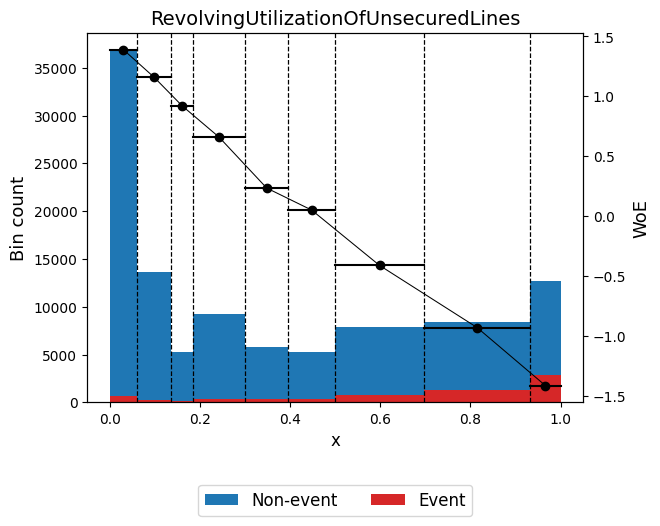

📊 Variabile: NumberOfTimes90DaysLate
Status: OPTIMAL
Splits: [0.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   99285   0.945571      94628   4657    0.046905   
1        [0.50, inf)    5715   0.054429       3354   2361    0.413123   
2            Special       0   0.000000          0      0    0.000000   
3            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.375276  0.113405  0.014093  
1      -2.285237  0.690575  0.071387  
2            0.0  0.000000  0.000000  
3            0.0  0.000000  0.000000  
Totals            0.803980  0.085480  


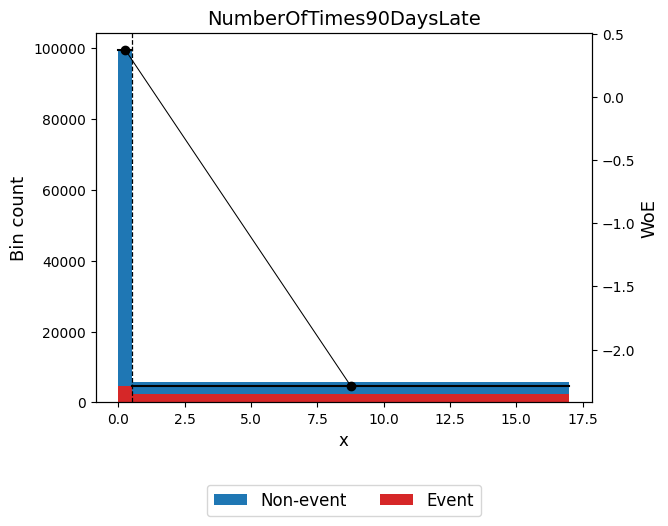

📊 Variabile: age
Status: OPTIMAL
Splits: [29.5 33.5 38.5 43.5 47.5 51.5 55.5 58.5 63.5 67.5 74.5]
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 29.50)    6198   0.059029       5492    706    0.113908   
1       [29.50, 33.50)    5745   0.054714       5121    624    0.108616   
2       [33.50, 38.50)    8321   0.079248       7512    809    0.097224   
3       [38.50, 43.50)   10901   0.103819       9931    970    0.088983   
4       [43.50, 47.50)   10007   0.095305       9207    800    0.079944   
5       [47.50, 51.50)   10480   0.099810       9665    815    0.077767   
6       [51.50, 55.50)    9988   0.095124       9299    689    0.068983   
7       [55.50, 58.50)    7351   0.070010       6938    413    0.056183   
8       [58.50, 63.50)   12176   0.115962      11607    569    0.046731   
9       [63.50, 67.50)    7455   0.071000       7213    242    0.032461   
10      [67.50, 74.50)    8492   0.080876       8277    215    0.025318   
11

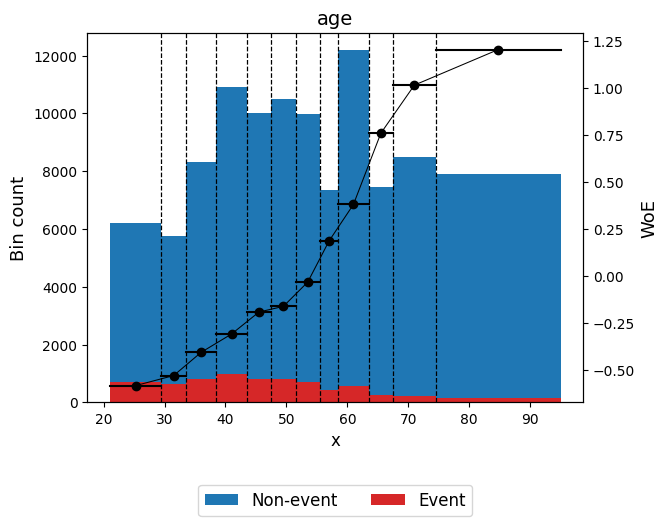

📊 Variabile: DebtRatio
Status: OPTIMAL
Splits: [0.13679758 0.22796316 0.2650307  0.34570184 0.42330818 0.50549355]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.14)   21307   0.202924      20001   1306    0.061294   
1       [0.14, 0.23)   12195   0.116143      11474    721    0.059123   
2       [0.23, 0.27)    5307   0.050543       5042    265    0.049934   
3       [0.27, 0.35)   10981   0.104581      10375    606    0.055186   
4       [0.35, 0.42)    9011   0.085819       8435    576    0.063922   
5       [0.42, 0.51)    7231   0.068867       6714    517    0.071498   
6        [0.51, inf)   38968   0.371124      35941   3027    0.077679   
7            Special       0   0.000000          0      0    0.000000   
8            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.092508  0.001669  0.000208  
1  

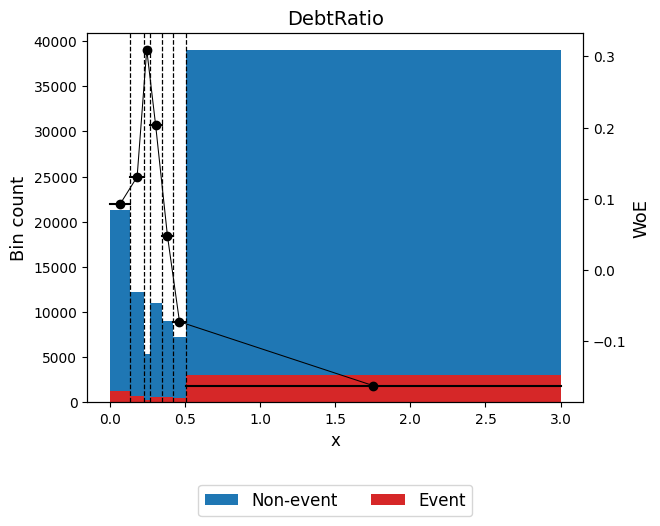

📊 Variabile: NumberOfOpenCreditLinesAndLoans
Status: OPTIMAL
Splits: [ 2.5  3.5  4.5  5.5  7.5  8.5 11.5 13.5 17.5]
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 2.50)    9042   0.086114       7868   1174    0.129839   
1         [2.50, 3.50)    6318   0.060171       5838    480    0.075973   
2         [3.50, 4.50)    8102   0.077162       7578    524    0.064675   
3         [4.50, 5.50)    9014   0.085848       8450    564    0.062569   
4         [5.50, 7.50)   18812   0.179162      17743   1069    0.056825   
5         [7.50, 8.50)    8809   0.083895       8386    423    0.048019   
6        [8.50, 11.50)   20496   0.195200      19302   1194    0.058255   
7       [11.50, 13.50)    8899   0.084752       8379    520    0.058434   
8       [13.50, 17.50)    9569   0.091133       8915    654    0.068346   
9         [17.50, inf)    5939   0.056562       5523    416    0.070045   
10             Special       0   0.000000          0      0

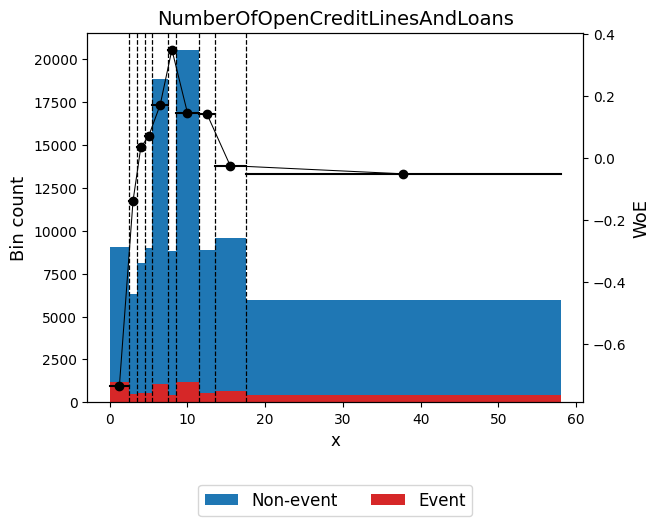

📊 Variabile: NumberOfTime60-89DaysPastDueNotWorse
Status: OPTIMAL
Splits: []
                Bin   Count  Count (%)  Non-event  Event  Event rate  WoE  \
0       (-inf, inf)  105000        1.0      97982   7018    0.066838  0.0   
1           Special       0        0.0          0      0    0.000000  0.0   
2           Missing       0        0.0          0      0    0.000000  0.0   
Totals               105000        1.0      97982   7018    0.066838        

         IV   JS  
0       0.0  0.0  
1       0.0  0.0  
2       0.0  0.0  
Totals  0.0  0.0  


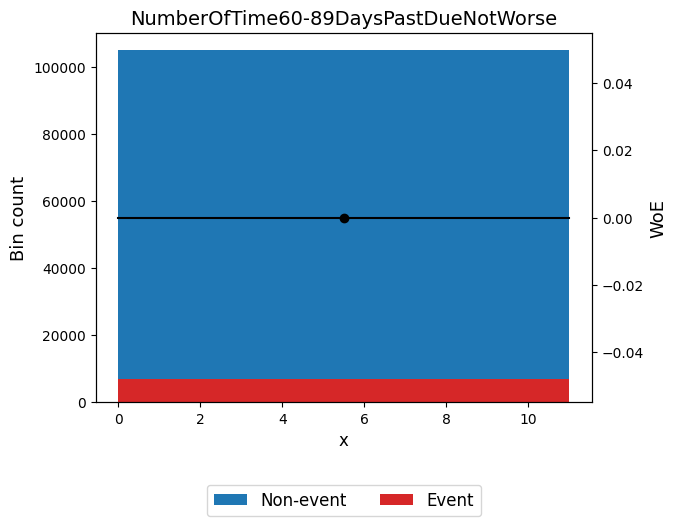

In [31]:
# === VISUALIZZAZIONE DEI BINNING OTTIMALI PER LE VARIABILI NUMERICHE ===
import matplotlib.pyplot as plt

# Variabili più importanti nel dataset Give Me Some Credit
vars_to_plot = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTimes90DaysLate",
    "age",
    "DebtRatio",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for var in vars_to_plot:
    print("=" * 60)
    print(f" Variabile: {var}")
    print("=" * 60)

    # Estrai oggetto OptimalBinning relativo a quella variabile
    bv = binning_process.get_binned_variable(var)

    # Stato del binning
    print("Status:", bv.status)

    # Cutpoint
    print("Splits:", bv.splits)

    # Tabella WoE/IV
    table = bv.binning_table.build()
    print(table)

    # Grafico WoE
    bv.binning_table.plot(metric="woe", style="actual", add_special=False, add_missing=False)
    plt.show()
    



In [32]:
# Check Per vedere se tutte le variabili sono state trasformate in WOE e se quindi sono tutte numeriche.
pd.set_option("display.max_columns", None)
print(X_train_woe.head())

   RevolvingUtilizationOfUnsecuredLines       age  \
0                              1.390402 -0.163227   
1                              1.390402 -0.407847   
2                              1.390402 -0.310185   
3                             -0.412458  0.185016   
4                             -0.412458 -0.407847   

   NumberOfTime30-59DaysPastDueNotWorse  DebtRatio  MonthlyIncome  \
0                              0.505632   0.092508      -0.108522   
1                              0.505632   0.047732      -0.487085   
2                              0.505632  -0.161999      -0.231179   
3                              0.505632   0.203969       0.474079   
4                              0.505632  -0.161999       0.127440   

   NumberOfOpenCreditLinesAndLoans  NumberOfTimes90DaysLate  \
0                         0.070562                 0.375276   
1                         0.035207                 0.375276   
2                         0.146594                 0.375276   
3             

📊 Variabile (binning manuale): NumberOfTime30-59DaysPastDueNotWorse
Status: OPTIMAL
Splits: [0.5 1.5 2.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   88360   0.841524      84701   3659    0.041410   
1       [0.50, 1.50)   11252   0.107162       9592   1660    0.147529   
2       [1.50, 2.50)    3225   0.030714       2359    866    0.268527   
3        [2.50, inf)    2163   0.020600       1330    833    0.385113   
4            Special       0   0.000000          0      0    0.000000   
5            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.505632  0.173473  0.021456  
1      -0.882194  0.122307  0.014811  
2      -1.634197  0.162310  0.018295  
3      -2.168405  0.227945  0.023963  
4            0.0  0.000000  0.000000  
5            0.0  0.000000  0.000000  
Totals            0.686034  0.078525

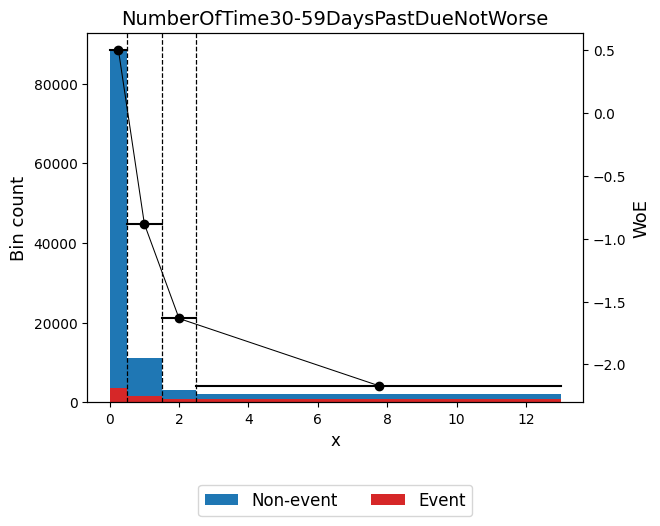

📊 Variabile (binning manuale): NumberOfTime60-89DaysPastDueNotWorse
Status: OPTIMAL
Splits: [0.5 1.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   99844   0.950895      94673   5171    0.051791   
1       [0.50, 1.50)    4049   0.038562       2787   1262    0.311682   
2        [1.50, inf)    1107   0.010543        522    585    0.528455   
3            Special       0   0.000000          0      0    0.000000   
4            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.271057  0.062183  0.007749  
1      -1.844038  0.279149  0.030662  
2       -2.75025  0.214601  0.020663  
3            0.0  0.000000  0.000000  
4            0.0  0.000000  0.000000  
Totals            0.555933  0.059074  


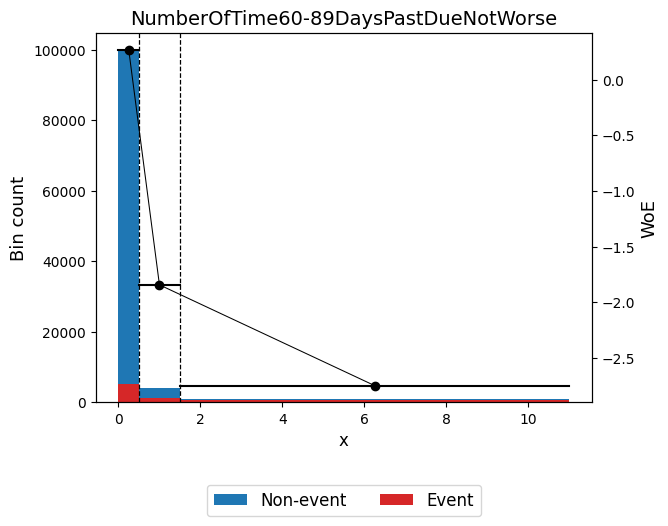

📊 Variabile (binning manuale): NumberOfTimes90DaysLate
Status: OPTIMAL
Splits: [0.5 1.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   99285   0.945571      94628   4657    0.046905   
1       [0.50, 1.50)    3723   0.035457       2462   1261    0.338705   
2        [1.50, inf)    1992   0.018971        892   1100    0.552209   
3            Special       0   0.000000          0      0    0.000000   
4            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.375276  0.113405  0.014093  
1      -1.967237  0.304044  0.032862  
2      -2.845905  0.420158  0.039841  
3            0.0  0.000000  0.000000  
4            0.0  0.000000  0.000000  
Totals            0.837607  0.086796  


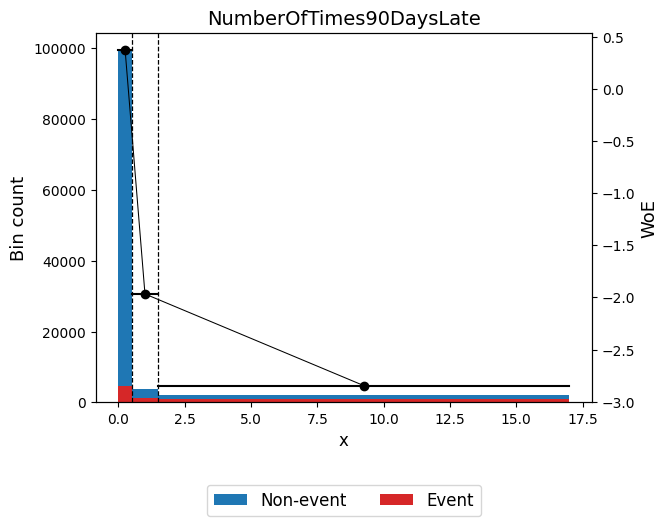

In [33]:
# === BINNING OTTIMIZZATO PER LE VARIABILI DI CONTEGGIO ===
from optbinning import OptimalBinning
import matplotlib.pyplot as plt

# Variabili di conteggio che davano problemi nel binning automatico
vars_time = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

for var in vars_time:
    print("=" * 70)
    print(f" Variabile (binning manuale): {var}")
    print("=" * 70)

    # Binning personalizzato con parametri rilassati
    bv = OptimalBinning(
        name=var,
        dtype="numerical",
        solver="cp",
        monotonic_trend=None,     # disattiva monotonicità
        max_n_prebins=20,         # più granularità
        min_prebin_size=0.01,     # consente bin piccoli
        min_bin_size=0.01,        # idem
        min_bin_n_nonevent=1,
        min_bin_n_event=1,
        verbose=False
    )

    # Fit su train
    bv.fit(X_train_imp[var], y_train)

    # Stato del binning
    print("Status:", bv.status)

    # Cutpoints trovati
    print("Splits:", bv.splits)

    # Tabella WoE / IV
    table = bv.binning_table.build()
    print(table)

    # Grafico WoE
    bv.binning_table.plot(metric="woe", style="actual", add_special=False, add_missing=False)
    plt.show()


📊 Variabile: RevolvingUtilizationOfUnsecuredLines
Status: OPTIMAL
Splits: [0.06041593 0.13687599 0.1841827  0.30089724 0.39893712 0.50030291
 0.59905213 0.69650653 0.77340057 0.85940111 0.93277419 0.99999994]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.06)   36814   0.350610      36169    645    0.017521   
1       [0.06, 0.14)   13646   0.129962      13346    300    0.021984   
2       [0.14, 0.18)    5303   0.050505       5156    147    0.027720   
3       [0.18, 0.30)    9265   0.088238       8934    331    0.035726   
4       [0.30, 0.40)    5976   0.056914       5658    318    0.053213   
5       [0.40, 0.50)    5088   0.048457       4759    329    0.064662   
6       [0.50, 0.60)    4179   0.039800       3800    379    0.090692   
7       [0.60, 0.70)    3667   0.034924       3280    387    0.105536   
8       [0.70, 0.77)    2649   0.025229       2299    350    0.132125   
9       [0.77, 0.86)    2921   0.027819       2476    445    

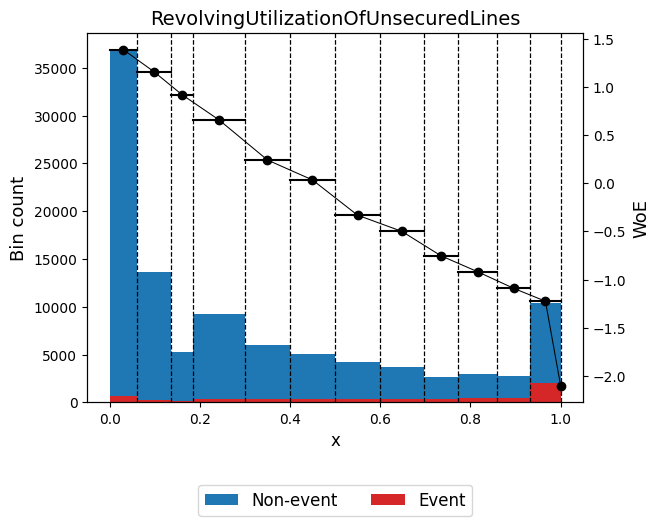

📊 Variabile: NumberOfTimes90DaysLate
Status: OPTIMAL
Splits: [0.5 1.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   99285   0.945571      94628   4657    0.046905   
1       [0.50, 1.50)    3723   0.035457       2462   1261    0.338705   
2        [1.50, inf)    1992   0.018971        892   1100    0.552209   
3            Special       0   0.000000          0      0    0.000000   
4            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.375276  0.113405  0.014093  
1      -1.967237  0.304044  0.032862  
2      -2.845905  0.420158  0.039841  
3            0.0  0.000000  0.000000  
4            0.0  0.000000  0.000000  
Totals            0.837607  0.086796  


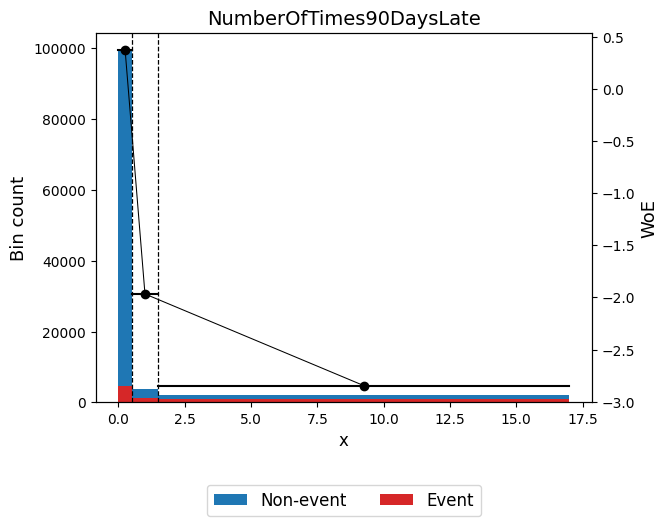

📊 Variabile: age
Status: OPTIMAL
Splits: [33.5 38.5 43.5 51.5 53.5 57.5 62.5 63.5 67.5 80.5]
                   Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 33.50)   11943   0.113743      10613   1330    0.111362   
1       [33.50, 38.50)    8321   0.079248       7512    809    0.097224   
2       [38.50, 43.50)   10901   0.103819       9931    970    0.088983   
3       [43.50, 51.50)   20487   0.195114      18872   1615    0.078830   
4       [51.50, 53.50)    5094   0.048514       4725    369    0.072438   
5       [53.50, 57.50)    9816   0.093486       9202    614    0.062551   
6       [57.50, 62.50)   11995   0.114238      11411    584    0.048687   
7       [62.50, 63.50)    2610   0.024857       2506    104    0.039847   
8       [63.50, 67.50)    7455   0.071000       7213    242    0.032461   
9       [67.50, 80.50)   12987   0.123686      12669    318    0.024486   
10        [80.50, inf)    3391   0.032295       3328     63    0.018579   
11     

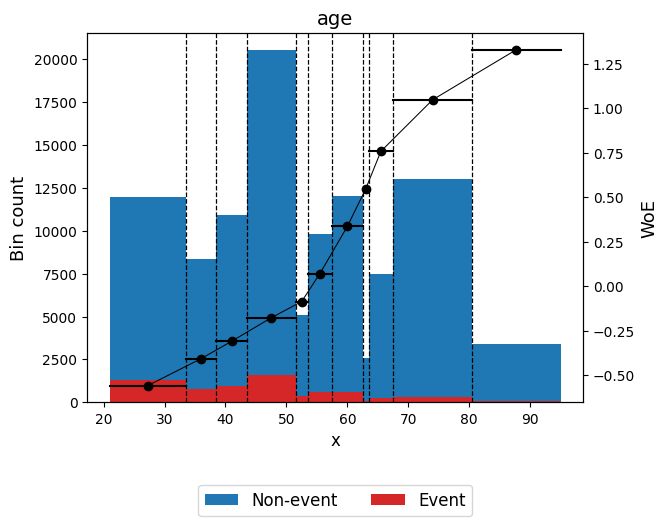

📊 Variabile: DebtRatio
Status: OPTIMAL
Splits: [0.01994902 0.34570184 0.42330818 0.50549355 0.5691984  0.69886789
 1.09687829 1.96320933]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.02)    9229   0.087895       8742    487    0.052768   
1       [0.02, 0.35)   40561   0.386295      38150   2411    0.059441   
2       [0.35, 0.42)    9011   0.085819       8435    576    0.063922   
3       [0.42, 0.51)    7231   0.068867       6714    517    0.071498   
4       [0.51, 0.57)    3973   0.037838       3628    345    0.086836   
5       [0.57, 0.70)    5300   0.050476       4787    513    0.096792   
6       [0.70, 1.10)    5895   0.056143       5208    687    0.116539   
7       [1.10, 1.96)    2047   0.019495       1750    297    0.145090   
8        [1.96, inf)   21753   0.207171      20568   1185    0.054475   
9            Special       0   0.000000          0      0    0.000000   
10           Missing       0   0.000000          0      0  

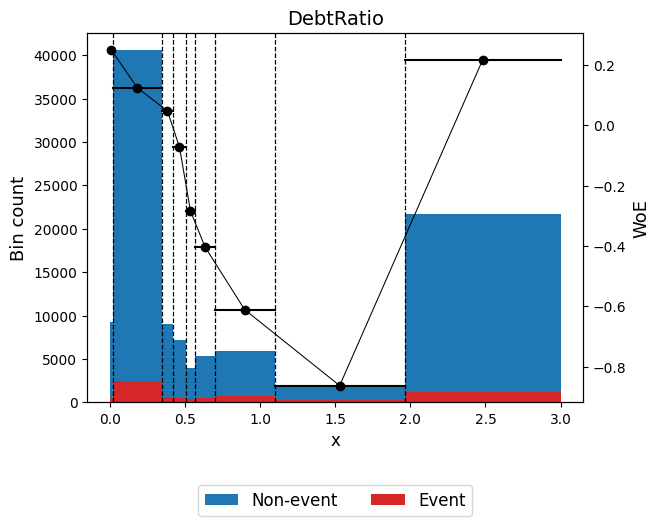

📊 Variabile: NumberOfOpenCreditLinesAndLoans
Status: OPTIMAL
Splits: [ 0.5  1.5  2.5  3.5  5.5  7.5  8.5 13.5]
                  Bin   Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 0.50)    1321   0.012581        976    345    0.261166   
1        [0.50, 1.50)    3114   0.029657       2706    408    0.131021   
2        [1.50, 2.50)    4607   0.043876       4186    421    0.091383   
3        [2.50, 3.50)    6318   0.060171       5838    480    0.075973   
4        [3.50, 5.50)   17116   0.163010      16028   1088    0.063566   
5        [5.50, 7.50)   18812   0.179162      17743   1069    0.056825   
6        [7.50, 8.50)    8809   0.083895       8386    423    0.048019   
7       [8.50, 13.50)   29395   0.279952      27681   1714    0.058309   
8        [13.50, inf)   15508   0.147695      14438   1070    0.068997   
9             Special       0   0.000000          0      0    0.000000   
10            Missing       0   0.000000          0      0    0.000000   
T

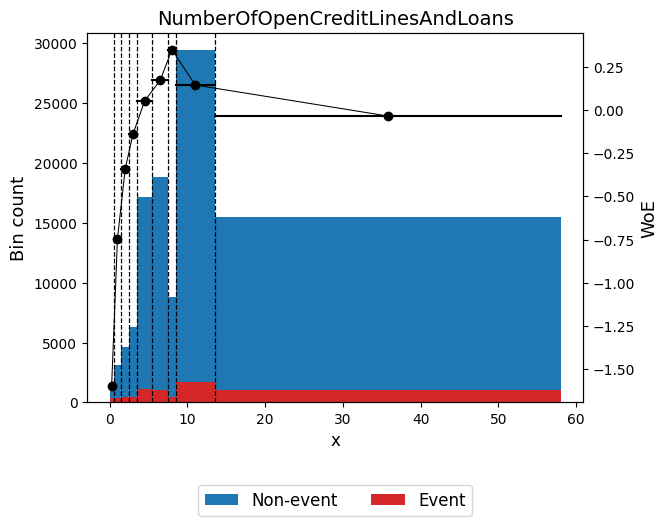

📊 Variabile: NumberOfTime60-89DaysPastDueNotWorse
Status: OPTIMAL
Splits: [0.5 1.5]
                 Bin   Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.50)   99844   0.950895      94673   5171    0.051791   
1       [0.50, 1.50)    4049   0.038562       2787   1262    0.311682   
2        [1.50, inf)    1107   0.010543        522    585    0.528455   
3            Special       0   0.000000          0      0    0.000000   
4            Missing       0   0.000000          0      0    0.000000   
Totals                105000   1.000000      97982   7018    0.066838   

             WoE        IV        JS  
0       0.271057  0.062183  0.007749  
1      -1.844038  0.279149  0.030662  
2       -2.75025  0.214601  0.020663  
3            0.0  0.000000  0.000000  
4            0.0  0.000000  0.000000  
Totals            0.555933  0.059074  


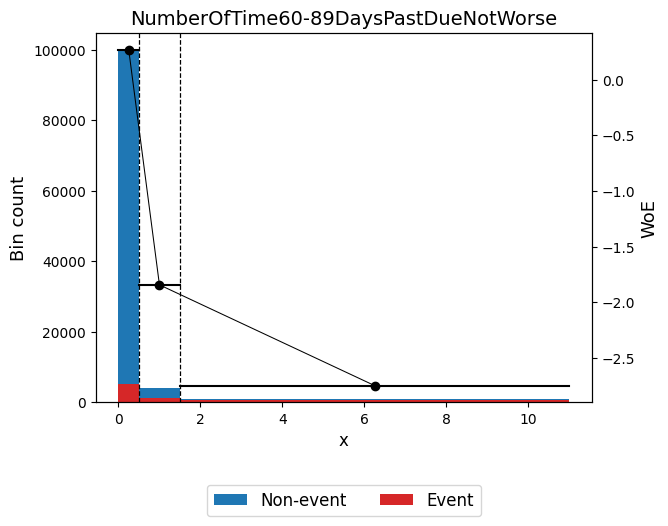

In [34]:
####BIN FINALE#####

from optbinning import BinningProcess

# === BINNING COMPLETO – versione migliorata ===

binning_process = BinningProcess(
    variable_names=list(X_train_imp.columns),
    categorical_variables=None,      # se hai solo variabili numeriche
    max_n_prebins=20,                # più pre-bin iniziali = maggiore flessibilità
    min_prebin_size=0.01,            # riduce la soglia minima per generare split
                
    max_pvalue=0.2,                  # meno restrittivo nel merging dei bin
    min_bin_size=0.01              # dimensione minima per bin finali
    
)

# Esegui il fitting
binning_process.fit(X_train_imp, y_train)

import matplotlib.pyplot as plt

vars_to_plot = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTimes90DaysLate",
    "age",
    "DebtRatio",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for var in vars_to_plot:
    print("=" * 60)
    print(f" Variabile: {var}")
    print("=" * 60)

    bv = binning_process.get_binned_variable(var)
    print("Status:", bv.status)
    print("Splits:", bv.splits)

    table = bv.binning_table.build()
    print(table)

    bv.binning_table.plot(metric="woe", style="actual", add_special=False, add_missing=False)
    plt.show()



In [35]:
X_train_woe = binning_process.transform(X_train_imp, metric="woe")
X_test_woe  = binning_process.transform(X_test_imp, metric="woe")

pd.set_option("display.max_columns", None)
print(X_train_woe.head())



   RevolvingUtilizationOfUnsecuredLines       age  \
0                              1.390402 -0.177961   
1                              1.390402 -0.407847   
2                              1.390402 -0.310185   
3                             -0.331085  0.070876   
4                             -0.499132 -0.407847   

   NumberOfTime30-59DaysPastDueNotWorse  DebtRatio  MonthlyIncome  \
0                              0.505632   0.125179      -0.108522   
1                              0.505632   0.047732      -0.439654   
2                              0.505632  -0.402922      -0.231179   
3                              0.505632   0.125179       0.474079   
4                              0.505632  -0.283413       0.139135   

   NumberOfOpenCreditLinesAndLoans  NumberOfTimes90DaysLate  \
0                         0.053691                 0.375276   
1                         0.053691                 0.375276   
2                         0.145611                 0.375276   
3             

In [36]:
# FIT LOGISTICA

import numpy as np

weights_train = np.where(y_train == 1, 2.0, 1.0)


In [37]:
import statsmodels.api as sm


# Riallinea gli indici per sicurezza
X_train_sm = sm.add_constant(X_train_woe).reset_index(drop=True)
X_test_sm  = sm.add_constant(X_test_woe).reset_index(drop=True)
y_train_aligned = y_train.reset_index(drop=True)

import statsmodels.api as sm

logit_full = sm.GLM(
    y_train_aligned, 
    X_train_sm, 
    family=sm.families.Binomial(), 
    freq_weights=weights_train
)
result_full = logit_full.fit()

print(result_full.summary())





                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:               105000
Model:                            GLM   Df Residuals:                   112007
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -30338.
Date:                Wed, 19 Nov 2025   Deviance:                       60676.
Time:                        11:56:01   Pearson chi2:                 1.00e+05
No. Iterations:                     6   Pseudo R-squ. (CS):             0.2033
Covariance Type:            nonrobust                                         
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


=== Logistic Regression (GLM) – Full Model ===
Accuracy: 0.9333
AUC: 0.8580

Confusion Matrix:
[[41049   943]
 [ 2059   949]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9522    0.9775    0.9647     41992
           1     0.5016    0.3155    0.3873      3008

    accuracy                         0.9333     45000
   macro avg     0.7269    0.6465    0.6760     45000
weighted avg     0.9221    0.9333    0.9261     45000



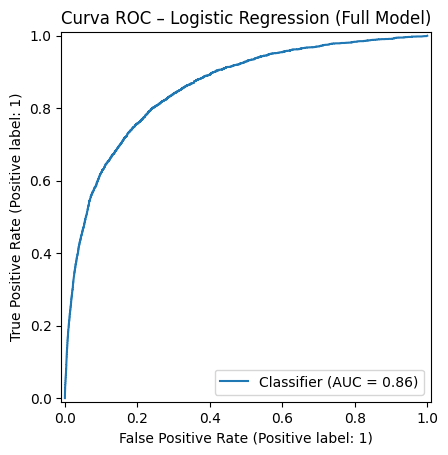

In [38]:
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# ===  Predizioni sul test set ===
y_pred_prob = result_full.predict(X_test_sm)
y_pred_class = (y_pred_prob >= 0.5).astype(int)   # soglia standard

# === Metriche principali ===
auc = roc_auc_score(y_test, y_pred_prob)
acc = accuracy_score(y_test, y_pred_class)

print("=== Logistic Regression (GLM) – Full Model ===")
print(f"Accuracy: {acc:.4f}")
print(f"AUC: {auc:.4f}")

# ===  Confusion matrix ===
cm = confusion_matrix(y_test, y_pred_class)
print("\nConfusion Matrix:")
print(cm)

# === Classification report (precision, recall, f1) ===
print("\nClassification Report:")
print(classification_report(y_test, y_pred_class, digits=4))

# ===  Curva ROC ===
RocCurveDisplay.from_predictions(y_test, y_pred_prob)
plt.title("Curva ROC – Logistic Regression (Full Model)")
plt.show()


In [39]:
import numpy as np
from sklearn.metrics import roc_curve, confusion_matrix, classification_report

# === Calcolo della curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

# === Calcolo del Youden Index ===
youden_index = tpr - fpr
best_threshold = thresholds[np.argmax(youden_index)]
best_J = np.max(youden_index)

print(f"Soglia ottimale (Youden): {best_threshold:.3f}")
print(f"Indice di Youden massimo: {best_J:.3f}")

# === Predizioni con soglia ottimale ===
y_pred_youden = (y_pred_prob >= best_threshold).astype(int)

# === Matrice di confusione ===
cm_youden = confusion_matrix(y_test, y_pred_youden)
print("\nMatrice di Confusione (Youden Index):")
print(cm_youden)

# === Classification report ===
print("\nClassification Report (Youden):")
print(classification_report(y_test, y_pred_youden, digits=4))


Soglia ottimale (Youden): 0.106
Indice di Youden massimo: 0.560

Matrice di Confusione (Youden Index):
[[32290  9702]
 [  630  2378]]

Classification Report (Youden):
              precision    recall  f1-score   support

           0     0.9809    0.7690    0.8621     41992
           1     0.1969    0.7906    0.3152      3008

    accuracy                         0.7704     45000
   macro avg     0.5889    0.7798    0.5886     45000
weighted avg     0.9285    0.7704    0.8255     45000



Soglia ottimale (Youden): 0.106
Tasso di veri positivi (TPR): 0.791
Tasso di falsi positivi (FPR): 0.231


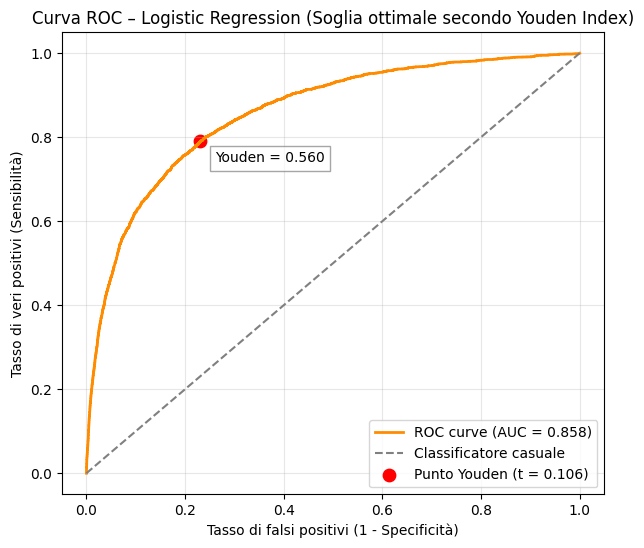

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ===  Calcolo ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# === Calcolo Youden Index ===
youden_index = tpr - fpr
best_idx = np.argmax(youden_index)
best_threshold = thresholds[best_idx]
best_tpr = tpr[best_idx]
best_fpr = fpr[best_idx]

print(f"Soglia ottimale (Youden): {best_threshold:.3f}")
print(f"Tasso di veri positivi (TPR): {best_tpr:.3f}")
print(f"Tasso di falsi positivi (FPR): {best_fpr:.3f}")

# ===  Grafico ROC ===
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Classificatore casuale")

# Evidenzia il punto di Youden
plt.scatter(best_fpr, best_tpr, color="red", s=80, label=f"Punto Youden (t = {best_threshold:.3f})")

# Annotazione sul grafico
plt.text(best_fpr + 0.03, best_tpr - 0.05,
         f"Youden = {youden_index[best_idx]:.3f}",
         fontsize=10, color="black", bbox=dict(facecolor="white", alpha=0.7, edgecolor="gray"))

plt.title("Curva ROC – Logistic Regression (Soglia ottimale secondo Youden Index)")
plt.xlabel("Tasso di falsi positivi (1 - Specificità)")
plt.ylabel("Tasso di veri positivi (Sensibilità)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


Soglia ottimale (Youden – EBM): 0.477
Indice di Youden massimo: 0.571
AUC (EBM): 0.864

Matrice di Confusione (EBM – Youden Index):
[[33407  8585]
 [  676  2332]]

Classification Report (EBM – Youden Index):
              precision    recall  f1-score   support

           0     0.9802    0.7956    0.8783     41992
           1     0.2136    0.7753    0.3349      3008

    accuracy                         0.7942     45000
   macro avg     0.5969    0.7854    0.6066     45000
weighted avg     0.9289    0.7942    0.8419     45000



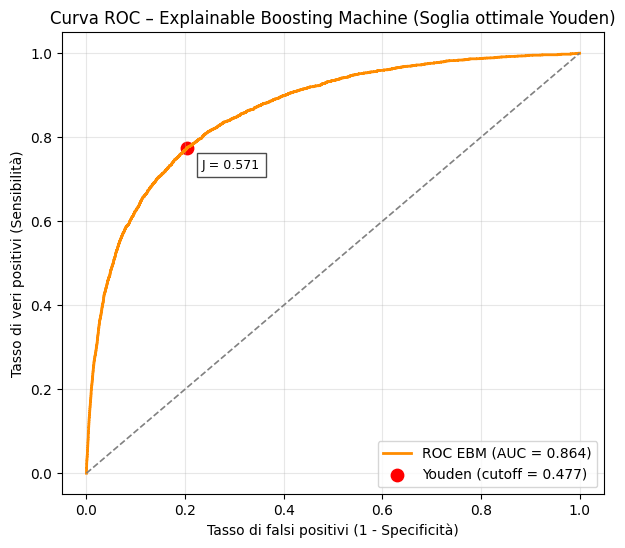


=== Confronto finale Logistica vs EBM ===


,Modello,AUC,Accuracy,Recall (1),Precision (1),F1 (1),Soglia Youden
0,Logistica,0.858,0.770,0.791,0.197,0.315,0.106
1,EBM,0.864,0.794,0.775,0.214,0.335,0.477


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score, confusion_matrix, classification_report
)

# ===  Predizioni di probabilità EBM ===
y_pred_prob_ebm = ebm_tuned.predict_proba(X_test)[:, 1]

# ===  Calcolo curva ROC e AUC ===
fpr_ebm, tpr_ebm, thresholds_ebm = roc_curve(y_test, y_pred_prob_ebm)
auc_ebm = roc_auc_score(y_test, y_pred_prob_ebm)

# ===  Calcolo del Youden Index ===
youden_index_ebm = tpr_ebm - fpr_ebm
best_idx_ebm = np.argmax(youden_index_ebm)
best_threshold_ebm = thresholds_ebm[best_idx_ebm]
best_tpr_ebm = tpr_ebm[best_idx_ebm]
best_fpr_ebm = fpr_ebm[best_idx_ebm]

print(f"Soglia ottimale (Youden – EBM): {best_threshold_ebm:.3f}")
print(f"Indice di Youden massimo: {youden_index_ebm[best_idx_ebm]:.3f}")
print(f"AUC (EBM): {auc_ebm:.3f}")

# === Predizioni binarie con soglia ottimale ===
y_pred_ebm_youden = (y_pred_prob_ebm >= best_threshold_ebm).astype(int)

# ===  Matrice di confusione e classification report ===
cm_ebm = confusion_matrix(y_test, y_pred_ebm_youden)
print("\nMatrice di Confusione (EBM – Youden Index):")
print(cm_ebm)

print("\nClassification Report (EBM – Youden Index):")
print(classification_report(y_test, y_pred_ebm_youden, digits=4))

# ===  Grafico ROC con punto Youden ===
plt.figure(figsize=(7,6))
plt.plot(fpr_ebm, tpr_ebm, color="darkorange", lw=2, label=f"ROC EBM (AUC = {auc_ebm:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1.2, linestyle="--")
plt.scatter(best_fpr_ebm, best_tpr_ebm, color="red", s=80,
            label=f"Youden (cutoff = {best_threshold_ebm:.3f})")
plt.text(best_fpr_ebm + 0.03, best_tpr_ebm - 0.05,
         f"J = {youden_index_ebm[best_idx_ebm]:.3f}",
         fontsize=9, color="black", bbox=dict(facecolor="white", alpha=0.7))
plt.title("Curva ROC – Explainable Boosting Machine (Soglia ottimale Youden)")
plt.xlabel("Tasso di falsi positivi (1 - Specificità)")
plt.ylabel("Tasso di veri positivi (Sensibilità)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# ===  Confronto finale EBM vs Logistica ===
# Assumiamo che tu abbia già y_pred_prob_logit e y_pred_logit_youden (o puoi ricalcolarlo)

# --- Logit: se già calcolato prima, puoi riutilizzare ---
auc_logit = 0.858   # inserisci qui il valore già ottenuto
youden_threshold_logit = 0.106
recall1_logit = 0.791
precision1_logit = 0.197
accuracy_logit = 0.770

# --- EBM: calcolo metriche principali ---
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

precision1_ebm = precision_score(y_test, y_pred_ebm_youden)
recall1_ebm = recall_score(y_test, y_pred_ebm_youden)
accuracy_ebm = accuracy_score(y_test, y_pred_ebm_youden)
f1_ebm = f1_score(y_test, y_pred_ebm_youden)

# --- Tabella comparativa ---
comparison = pd.DataFrame({
    "Modello": ["Logistica", "EBM"],
    "AUC": [auc_logit, auc_ebm],
    "Accuracy": [accuracy_logit, accuracy_ebm],
    "Recall (1)": [recall1_logit, recall1_ebm],
    "Precision (1)": [precision1_logit, precision1_ebm],
    "F1 (1)": [0.315, f1_ebm],
    "Soglia Youden": [youden_threshold_logit, best_threshold_ebm]
})
print("\n=== Confronto finale Logistica vs EBM ===")
display(comparison.round(3))


### CONFRONTO FINALE ###

In [46]:
# --- Tabella comparativa ---
comparison = pd.DataFrame({
    "Modello": ["Logistica", "EBM"],
    "AUC": [auc_logit, auc_ebm],
    "Accuracy": [accuracy_logit, accuracy_ebm],
    " Sensibilità (Recall 1)": [recall1_logit, recall1_ebm],
    "Specificità (Recall 0)": [0.769, 0.795],
    "Precision (1)": [precision1_logit, precision1_ebm]
    
    
})
print("\n=== Confronto finale Logistica vs EBM ===")
display(comparison.round(3))

cm_ebm = confusion_matrix(y_test, y_pred_ebm_youden)
print("\nMatrice di Confusione (EBM – Youden Index):")
print(cm_ebm)

# === Matrice di confusione ===
cm_youden = confusion_matrix(y_test, y_pred_youden)
print("\nMatrice di Confusione (Logistica- Youden Index):")
print(cm_youden)



=== Confronto finale Logistica vs EBM ===


,Modello,AUC,Accuracy,Sensibilità (Recall 1),Specificità (Recall 0),Precision (1)
0,Logistica,0.858,0.770,0.791,0.769,0.197
1,EBM,0.864,0.794,0.775,0.795,0.214



Matrice di Confusione (EBM – Youden Index):
[[33407  8585]
 [  676  2332]]

Matrice di Confusione (Logistica- Youden Index):
[[32290  9702]
 [  630  2378]]
